# 第9章：为什么平均多个模型

**学生实验｜全书深化稿**

## 背景与数据
Wine比较单树、Bagging和森林；预测方差公式通过受控相关误差模拟检查。

## 本次要回答的问题
分开改变树数和特征随机性，报告各次种子结果、OOB及验证用途。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 9: averaging, error correlation, finite forest size and OOB."""
import numpy as np
from sklearn.ensemble import RandomForestClassifier,BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from common import *

def run():
    Xtr,Xva,ytr,yva,_=development_trainval('wine');rows=[]
    for trees in [10,30,100,300]:
        for seed in range(5):
            m=RandomForestClassifier(n_estimators=trees,max_features='sqrt',random_state=seed,n_jobs=1)
            m.fit(Xtr,ytr);rows.append({'trees':trees,'seed':seed,'validation_accuracy':m.score(Xva,yva)})
    df=table('ch09_forest_seeds',rows);summary=df.groupby('trees').validation_accuracy.agg(['mean','std']).reset_index();table('ch09_forest_summary',summary);show_result(summary)
    plt.figure(figsize=(6.4,4));plt.errorbar(summary.trees,summary['mean'],yerr=summary['std'],marker='o');plt.xlabel('树数量');plt.ylabel('验证准确率（误差棒为种子间标准差）');figure('v3_ch09_tree_count')
    X,y,_=development('wine');splits=list(cv5().split(X,y));rows=[]
    models={'deep tree':DecisionTreeClassifier(random_state=42),
       'bagging':BaggingClassifier(DecisionTreeClassifier(),n_estimators=100,random_state=42,n_jobs=1),
       'forest':RandomForestClassifier(n_estimators=100,max_features='sqrt',random_state=42,n_jobs=1)}
    for name,m in models.items():
        s=cross_val_score(m,X,y,cv=splits,scoring='accuracy');rows.append({'model':name,'mean_accuracy':s.mean(),'std_accuracy':s.std()})
    df2=table('ch09_models',rows);show_result(df2)
    oob=RandomForestClassifier(n_estimators=300,oob_score=True,random_state=42,n_jobs=1).fit(Xtr,ytr)
    dump('ch09_oob',{'training_n':len(ytr),'oob_accuracy':oob.oob_score_,'validation_accuracy':oob.score(Xva,yva),'probability_left_out_finite':(1-1/len(ytr))**len(ytr)})
    # Direct Monte Carlo verification of an explicitly idealized covariance model.
    rng=np.random.default_rng(90);rows=[]
    for B in [1,5,20,100]:
        for rho in [0,.2,.8]:
            shared=rng.normal(size=(20000,1));ind=rng.normal(size=(20000,B))
            e=np.sqrt(rho)*shared+np.sqrt(1-rho)*ind
            rows.append({'models':B,'correlation':rho,'theory_variance':rho+(1-rho)/B,'simulated_variance':e.mean(axis=1).var()})
    table('ch09_variance',rows)
    plt.figure(figsize=(6.4,4));B=np.arange(1,101)
    for rho in [0,.2,.8]:plt.plot(B,rho+(1-rho)/B,label=f'rho={rho}')
    plt.xlabel('模型数 B');plt.ylabel('平均预测的理论方差（单模型方差=1）');plt.legend();figure('v3_ch09_correlation')

In [3]:
result = run()
if result is not None:
    print(result)

 trees     mean      std
    10 0.977778 0.023241
    30 0.988889 0.015215
   100 1.000000 0.000000
   300 1.000000 0.000000


    model  mean_accuracy  std_accuracy
deep tree       0.922660      0.026106
  bagging       0.950985      0.027849
   forest       0.985961      0.017199


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch09_correlation.png


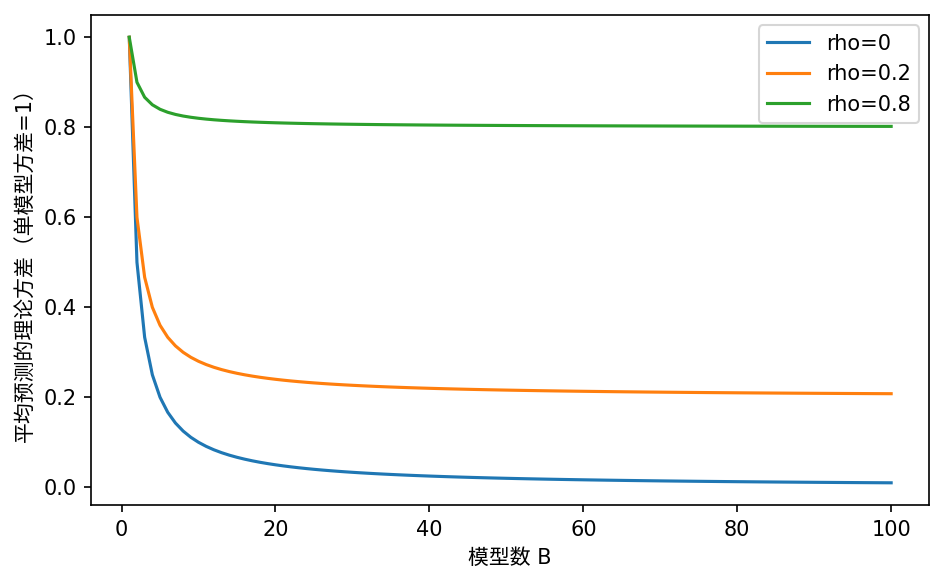

v3_ch09_tree_count.png


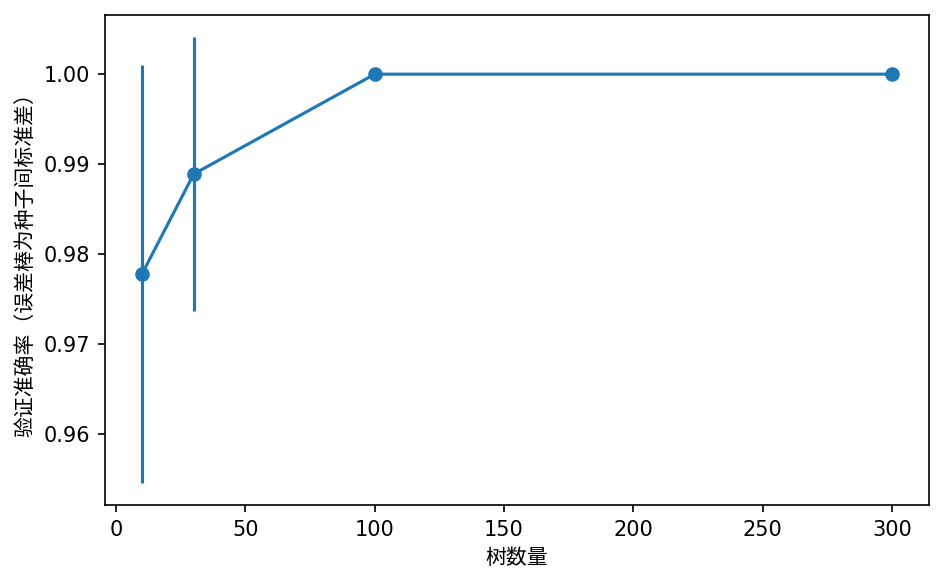

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch09_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

分开改变树数和特征随机性，报告各次种子结果、OOB及验证用途。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。